<a href="https://colab.research.google.com/github/omkashid214-ops/Weather-ETL-Pipeline/blob/main/Weather_ETL_Pipeline_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1 – Install and import libraries

In [1]:
!pip install pandas numpy matplotlib seaborn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os

from google.colab import files
from datetime import datetime

print("All libraries imported successfully!")
print("Weather ETL Pipeline is ready.")

All libraries imported successfully!
Weather ETL Pipeline is ready.


Step 2 – Create weather dataset

In [2]:
np.random.seed(42)

cities = ["Pune", "Mumbai", "Delhi", "Nashik", "Nagpur"]

dates = pd.date_range(
    start="2026-01-01",
    periods=30,
    freq="D"
)

data = []

for date in dates:
    for city in cities:

        temperature = np.random.uniform(18, 40)
        humidity = np.random.uniform(30, 95)
        wind = np.random.uniform(2, 30)
        pressure = np.random.uniform(990, 1020)
        rainfall = np.random.uniform(0, 25)

        if rainfall > 15:
            condition = "Rainy"
        elif temperature > 33:
            condition = "Sunny"
        elif humidity > 80:
            condition = "Cloudy"
        else:
            condition = "Clear"

        data.append([
            date, city, temperature,
            humidity, wind, pressure,
            rainfall, condition
        ])

columns = [
    "Date", "City", "Temperature",
    "Humidity", "Wind_Speed",
    "Pressure", "Rainfall",
    "Weather_Condition"
]

weather_df = pd.DataFrame(
    data,
    columns=columns
)

# Add missing values to demonstrate cleaning
weather_df.loc[5, "Temperature"] = np.nan
weather_df.loc[12, "Humidity"] = np.nan
weather_df.loc[20, "Rainfall"] = np.nan

# Add duplicate records
weather_df = pd.concat(
    [weather_df, weather_df.iloc[[0, 5]]],
    ignore_index=True
)

weather_df.to_csv(
    "weather_data.csv",
    index=False
)

print("Weather dataset created successfully!")
display(weather_df.head(10))

Weather dataset created successfully!


,Date,City,Temperature,Humidity,Wind_Speed,Pressure,Rainfall,Weather_Condition
0,2026-01-01,Pune,26.239883,91.796430,22.495830,1007.959755,3.900466,Cloudy
1,2026-01-01,Mumbai,21.431879,33.775435,26.252932,1008.033450,17.701814,Rainy
2,2026-01-01,Delhi,18.452859,93.044140,25.308394,996.370173,4.545624,Cloudy
3,2026-01-01,Nashik,22.034899,49.775746,16.693180,1002.958351,7.280729,Clear
4,2026-01-01,Nagpur,31.460764,39.067101,10.180050,1000.990855,11.401750,Clear
5,2026-01-02,Pune,NaN,42.978796,16.398564,1007.772437,1.161260,Sunny
6,2026-01-02,Mumbai,31.365987,41.084068,3.821445,1018.466566,24.140801,Rainy
7,2026-01-02,Delhi,35.784742,49.799895,4.734819,1010.526991,11.003812,Sunny
8,2026-01-02,Nashik,20.684841,62.186499,2.962879,1017.279612,6.469500,Clear
9,2026-01-02,Nagpur,32.575490,50.261220,16.561905,1006.401308,4.621361,Clear


Step 3 – Upload your own CSV (optional)

In [3]:
USE_UPLOADED_FILE = False

if USE_UPLOADED_FILE:
    uploaded = files.upload()
    csv_file = list(uploaded.keys())[0]
else:
    csv_file = "weather_data.csv"

print("Selected file:", csv_file)

Selected file: weather_data.csv


Step 4 – EXTRACT: Read the CSV file

In [4]:
df = pd.read_csv(csv_file)

print("EXTRACTION COMPLETED")
print("--------------------")

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

display(df.head())

print("\nDataset Information:")
df.info()

EXTRACTION COMPLETED
--------------------
Total Records: 152
Total Columns: 8


,Date,City,Temperature,Humidity,Wind_Speed,Pressure,Rainfall,Weather_Condition
0,2026-01-01,Pune,26.239883,91.796430,22.495830,1007.959755,3.900466,Cloudy
1,2026-01-01,Mumbai,21.431879,33.775435,26.252932,1008.033450,17.701814,Rainy
2,2026-01-01,Delhi,18.452859,93.044140,25.308394,996.370173,4.545624,Cloudy
3,2026-01-01,Nashik,22.034899,49.775746,16.693180,1002.958351,7.280729,Clear
4,2026-01-01,Nagpur,31.460764,39.067101,10.180050,1000.990855,11.401750,Clear



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               152 non-null    object 
 1   City               152 non-null    object 
 2   Temperature        150 non-null    float64
 3   Humidity           151 non-null    float64
 4   Wind_Speed         152 non-null    float64
 5   Pressure           152 non-null    float64
 6   Rainfall           151 non-null    float64
 7   Weather_Condition  152 non-null    object 
dtypes: float64(5), object(3)
memory usage: 9.6+ KB


Step 5 – Analyze the raw data

In [5]:
print("MISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe())

print("\nDATA SHAPE")
print(df.shape)

MISSING VALUES
Date                 0
City                 0
Temperature          2
Humidity             1
Wind_Speed           0
Pressure             0
Rainfall             1
Weather_Condition    0
dtype: int64

DUPLICATE RECORDS
2

STATISTICAL SUMMARY


,Temperature,Humidity,Wind_Speed,Pressure,Rainfall
count,150.000000,151.000000,152.000000,152.000000,151.000000
mean,29.217823,63.092117,15.611859,1005.330853,11.301681
std,6.565395,19.264594,8.027553,8.660404,7.466423
min,18.202335,30.737987,2.154619,990.151848,0.386415
25%,23.706955,47.436028,8.312246,997.967778,4.055800
50%,29.051178,63.721390,16.180079,1005.650597,10.259921
75%,35.070270,80.258103,22.594187,1012.761785,17.973734
max,39.845226,94.981649,29.905831,1019.618284,24.672173



DATA SHAPE
(152, 8)


Step 6 – TRANSFORM: Clean the weather data

In [6]:
# Make a copy of raw data
clean_df = df.copy()

# Remove duplicate records
clean_df = clean_df.drop_duplicates()

# Clean city names
clean_df["City"] = (
    clean_df["City"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Convert date into datetime format
clean_df["Date"] = pd.to_datetime(
    clean_df["Date"],
    errors="coerce"
)

# Convert numeric columns
numeric_cols = [
    "Temperature", "Humidity",
    "Wind_Speed", "Pressure", "Rainfall"
]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(
        clean_df[col],
        errors="coerce"
    )

# Handle invalid measurements
valid_ranges = {
    "Temperature": (-50, 60),
    "Humidity": (0, 100),
    "Wind_Speed": (0, 200),
    "Pressure": (800, 1100),
    "Rainfall": (0, 500)
}

for col, (low, high) in valid_ranges.items():
    clean_df.loc[
        ~clean_df[col].between(low, high),
        col
    ] = np.nan

# Remove records with invalid dates or missing city
clean_df = clean_df.dropna(
    subset=["Date", "City"]
)

# Fill missing numeric values using city median
for col in numeric_cols:
    clean_df[col] = clean_df.groupby("City")[col].transform(
        lambda x: x.fillna(x.median())
    )

    clean_df[col] = clean_df[col].fillna(
        clean_df[col].median()
    )

# Handle missing weather conditions
clean_df["Weather_Condition"] = (
    clean_df["Weather_Condition"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .str.title()
)

print("DATA CLEANING COMPLETED")
print("Original records:", len(df))
print("Cleaned records:", len(clean_df))

print("\nRemaining missing values:")
print(clean_df.isnull().sum())

DATA CLEANING COMPLETED
Original records: 152
Cleaned records: 150

Remaining missing values:
Date                 0
City                 0
Temperature          0
Humidity             0
Wind_Speed           0
Pressure             0
Rainfall             0
Weather_Condition    0
dtype: int64


Step 7 – Feature engineering

In [7]:
# Extract date components
clean_df["Year"] = clean_df["Date"].dt.year
clean_df["Month"] = clean_df["Date"].dt.month
clean_df["Day"] = clean_df["Date"].dt.day

# Temperature categorization
clean_df["Temperature_Category"] = pd.cut(
    clean_df["Temperature"],
    bins=[-51, 20, 30, 60],
    labels=["Cold", "Moderate", "Hot"]
)

# Rainfall categorization
clean_df["Rainfall_Category"] = pd.cut(
    clean_df["Rainfall"],
    bins=[-0.01, 0, 5, 20, 500],
    labels=["No Rain", "Light Rain",
            "Moderate Rain", "Heavy Rain"]
)

# Additional indicators
clean_df["Is_Hot_Day"] = (
    clean_df["Temperature"] > 35
)

clean_df["Is_Rainy_Day"] = (
    clean_df["Rainfall"] > 0
)

print("FEATURE ENGINEERING COMPLETED")

display(clean_df.head(10))

FEATURE ENGINEERING COMPLETED


,Date,City,Temperature,Humidity,Wind_Speed,Pressure,Rainfall,Weather_Condition,Year,Month,Day,Temperature_Category,Rainfall_Category,Is_Hot_Day,Is_Rainy_Day
0,2026-01-01,Pune,26.239883,91.796430,22.495830,1007.959755,3.900466,Cloudy,2026,1,1,Moderate,Light Rain,False,True
1,2026-01-01,Mumbai,21.431879,33.775435,26.252932,1008.033450,17.701814,Rainy,2026,1,1,Moderate,Moderate Rain,False,True
2,2026-01-01,Delhi,18.452859,93.044140,25.308394,996.370173,4.545624,Cloudy,2026,1,1,Cold,Light Rain,False,True
3,2026-01-01,Nashik,22.034899,49.775746,16.693180,1002.958351,7.280729,Clear,2026,1,1,Moderate,Moderate Rain,False,True
4,2026-01-01,Nagpur,31.460764,39.067101,10.180050,1000.990855,11.401750,Clear,2026,1,1,Hot,Moderate Rain,False,True
5,2026-01-02,Pune,29.068998,42.978796,16.398564,1007.772437,1.161260,Sunny,2026,1,2,Moderate,Light Rain,False,True
6,2026-01-02,Mumbai,31.365987,41.084068,3.821445,1018.466566,24.140801,Rainy,2026,1,2,Hot,Heavy Rain,False,True
7,2026-01-02,Delhi,35.784742,49.799895,4.734819,1010.526991,11.003812,Sunny,2026,1,2,Hot,Moderate Rain,True,True
8,2026-01-02,Nashik,20.684841,62.186499,2.962879,1017.279612,6.469500,Clear,2026,1,2,Moderate,Moderate Rain,False,True
9,2026-01-02,Nagpur,32.575490,50.261220,16.561905,1006.401308,4.621361,Clear,2026,1,2,Hot,Light Rain,False,True


Step 8 – Validate transformed data

In [8]:
print("DATA VALIDATION REPORT")
print("----------------------")

print("Missing values:",
      clean_df.isnull().sum().sum())

print("Duplicate records:",
      clean_df.duplicated().sum())

print("Invalid temperature:",
      (~clean_df["Temperature"].between(-50, 60)).sum())

print("Invalid humidity:",
      (~clean_df["Humidity"].between(0, 100)).sum())

print("Final dataset shape:",
      clean_df.shape)

assert clean_df.isnull().sum().sum() == 0
assert clean_df.duplicated().sum() == 0

print("\nAll validation checks passed!")

DATA VALIDATION REPORT
----------------------
Missing values: 0
Duplicate records: 0
Invalid temperature: 0
Invalid humidity: 0
Final dataset shape: (150, 15)

All validation checks passed!


5. LOAD: Store data in SQLite database

Step 9 – Generate analytical summary tables

In [9]:
# Daily weather summary
daily_summary = clean_df.groupby("Date").agg(
    Average_Temperature=("Temperature", "mean"),
    Average_Humidity=("Humidity", "mean"),
    Total_Rainfall=("Rainfall", "sum"),
    Average_Wind_Speed=("Wind_Speed", "mean")
).reset_index()

# City-wise weather summary
city_summary = clean_df.groupby("City").agg(
    Average_Temperature=("Temperature", "mean"),
    Average_Humidity=("Humidity", "mean"),
    Total_Rainfall=("Rainfall", "sum"),
    Maximum_Temperature=("Temperature", "max"),
    Minimum_Temperature=("Temperature", "min")
).reset_index()

# Weather condition summary
condition_summary = clean_df.groupby(
    "Weather_Condition"
).size().reset_index(name="Record_Count")

print("DAILY SUMMARY")
display(daily_summary.head())

print("CITY SUMMARY")
display(city_summary)

print("WEATHER CONDITION SUMMARY")
display(condition_summary)

DAILY SUMMARY


,Date,Average_Temperature,Average_Humidity,Total_Rainfall,Average_Wind_Speed
0,2026-01-01,23.924057,61.491770,44.830383,20.186077
1,2026-01-02,29.896012,49.262096,47.396734,8.895922
2,2026-01-03,33.818339,53.073413,72.447727,17.522855
3,2026-01-04,29.135009,73.681979,44.448123,14.492627
4,2026-01-05,27.897244,67.801114,43.987896,16.023399


CITY SUMMARY


,City,Average_Temperature,Average_Humidity,Total_Rainfall,Maximum_Temperature,Minimum_Temperature
0,Delhi,28.527320,64.981441,346.501431,38.784846,18.452859
1,Mumbai,29.303048,60.109748,348.498751,39.779125,18.202335
2,Nagpur,30.662614,64.779446,372.111433,38.839469,18.267398
3,Nashik,28.358982,61.600755,341.073290,39.791113,18.441566
4,Pune,29.331455,63.838252,300.353610,39.845226,18.691442


WEATHER CONDITION SUMMARY


,Weather_Condition,Record_Count
0,Clear,43
1,Cloudy,16
2,Rainy,56
3,Sunny,35


Step 10 – Create SQLite database

In [10]:
database_name = "weather_database.db"

conn = sqlite3.connect(database_name)

# Load transformed data
clean_df.to_sql(
    "Weather_Data",
    conn,
    if_exists="replace",
    index=False
)

# Load summary tables
daily_summary.to_sql(
    "Daily_Summary",
    conn,
    if_exists="replace",
    index=False
)

city_summary.to_sql(
    "City_Summary",
    conn,
    if_exists="replace",
    index=False
)

condition_summary.to_sql(
    "Condition_Summary",
    conn,
    if_exists="replace",
    index=False
)

print("DATA LOADED SUCCESSFULLY!")
print("Database:", database_name)

conn.close()

DATA LOADED SUCCESSFULLY!
Database: weather_database.db


Step 11 – Verify database using SQL

In [11]:
conn = sqlite3.connect("weather_database.db")

query = """
SELECT
    City,
    ROUND(AVG(Temperature), 2) AS Avg_Temperature,
    ROUND(AVG(Humidity), 2) AS Avg_Humidity,
    ROUND(SUM(Rainfall), 2) AS Total_Rainfall
FROM Weather_Data
GROUP BY City
ORDER BY Avg_Temperature DESC;
"""

result = pd.read_sql_query(query, conn)

print("CITY-WISE WEATHER ANALYSIS")
display(result)

conn.close()

CITY-WISE WEATHER ANALYSIS


,City,Avg_Temperature,Avg_Humidity,Total_Rainfall
0,Nagpur,30.66,64.78,372.11
1,Pune,29.33,63.84,300.35
2,Mumbai,29.30,60.11,348.50
3,Delhi,28.53,64.98,346.50
4,Nashik,28.36,61.60,341.07


6. Weather Analytics Dashboard


Step 12 – Generate visualizations

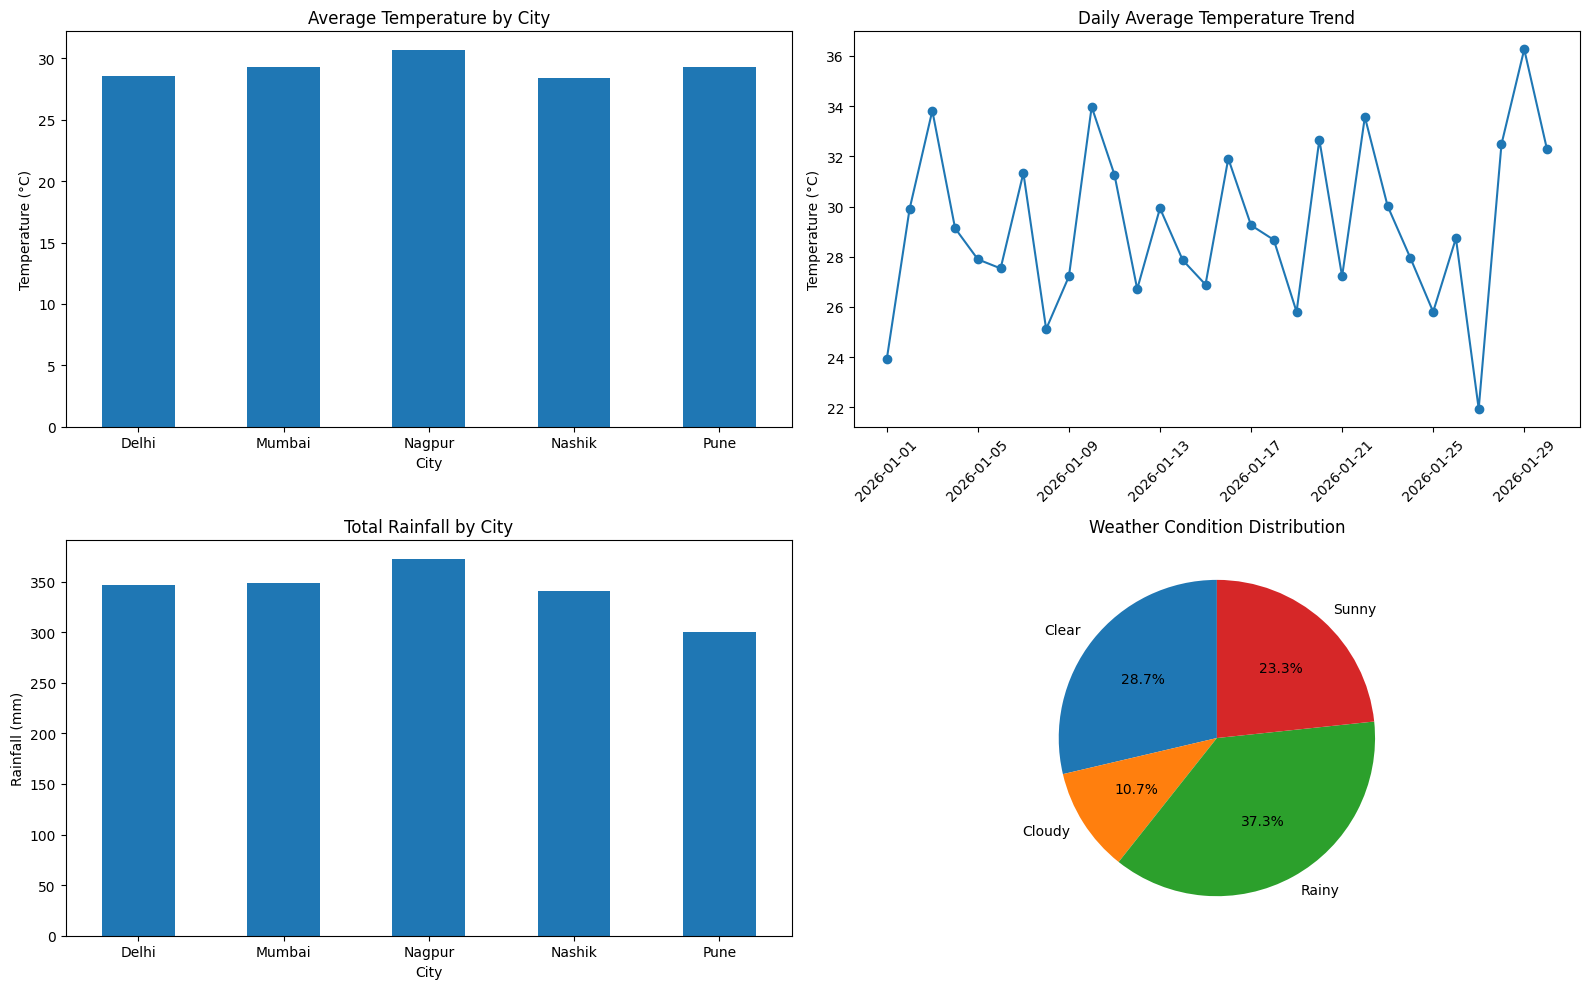

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Chart 1: Average temperature by city
city_summary.plot(
    x="City",
    y="Average_Temperature",
    kind="bar",
    ax=axes[0, 0],
    legend=False
)

axes[0, 0].set_title("Average Temperature by City")
axes[0, 0].set_ylabel("Temperature (°C)")
axes[0, 0].tick_params(axis="x", rotation=0)

# Chart 2: Daily temperature trend
axes[0, 1].plot(
    daily_summary["Date"],
    daily_summary["Average_Temperature"],
    marker="o"
)

axes[0, 1].set_title("Daily Average Temperature Trend")
axes[0, 1].set_ylabel("Temperature (°C)")
axes[0, 1].tick_params(axis="x", rotation=45)

# Chart 3: Total rainfall by city
city_summary.plot(
    x="City",
    y="Total_Rainfall",
    kind="bar",
    ax=axes[1, 0],
    legend=False
)

axes[1, 0].set_title("Total Rainfall by City")
axes[1, 0].set_ylabel("Rainfall (mm)")
axes[1, 0].tick_params(axis="x", rotation=0)

# Chart 4: Weather condition distribution
axes[1, 1].pie(
    condition_summary["Record_Count"],
    labels=condition_summary["Weather_Condition"],
    autopct="%1.1f%%",
    startangle=90
)

axes[1, 1].set_title("Weather Condition Distribution")

plt.tight_layout()

plt.savefig(
    "weather_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 13 – Generate project KPIs

In [13]:
total_records = len(clean_df)

total_cities = clean_df["City"].nunique()

avg_temperature = clean_df["Temperature"].mean()

avg_humidity = clean_df["Humidity"].mean()

total_rainfall = clean_df["Rainfall"].sum()

hot_days = clean_df["Is_Hot_Day"].sum()

rainy_records = clean_df["Is_Rainy_Day"].sum()

print("================================")
print("       WEATHER DASHBOARD")
print("================================")

print("Total Weather Records:", total_records)
print("Total Cities:", total_cities)

print("Average Temperature:",
      round(avg_temperature, 2), "°C")

print("Average Humidity:",
      round(avg_humidity, 2), "%")

print("Total Rainfall:",
      round(total_rainfall, 2), "mm")

print("Hot Weather Records:", hot_days)

print("Rainy Weather Records:", rainy_records)

print("================================")

       WEATHER DASHBOARD
Total Weather Records: 150
Total Cities: 5
Average Temperature: 29.24 °C
Average Humidity: 63.06 %
Total Rainfall: 1708.54 mm
Hot Weather Records: 38
Rainy Weather Records: 150


7. Export final project files

Step 14 – Save cleaned dataset and reports

In [14]:
clean_df.to_csv(
    "cleaned_weather_data.csv",
    index=False
)

daily_summary.to_csv(
    "daily_weather_summary.csv",
    index=False
)

city_summary.to_csv(
    "city_weather_summary.csv",
    index=False
)

condition_summary.to_csv(
    "weather_condition_summary.csv",
    index=False
)

print("All CSV reports exported successfully!")

All CSV reports exported successfully!


Step 15 – Download complete project output

In [15]:
import zipfile

output_files = [
    "weather_data.csv",
    "cleaned_weather_data.csv",
    "daily_weather_summary.csv",
    "city_weather_summary.csv",
    "weather_condition_summary.csv",
    "weather_database.db",
    "weather_dashboard.png"
]

with zipfile.ZipFile(
    "Weather_ETL_Project_Output.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file in output_files:
        zipf.write(file)

print("PROJECT OUTPUT ZIP CREATED!")

files.download("Weather_ETL_Project_Output.zip")

PROJECT OUTPUT ZIP CREATED!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>